# 81. Numerical Wahba and hybrid fusion verification (002.27)
No training. Verify the raw numerical estimates, angular correspondences, runtime, and identity-initialized hybrid on real KAIST windows. Install `hybrid_wahba_patch.zip` first. All faults are injected into calibration priors, not sensor noise. Ground truth is used only for evaluation and synthetic fault construction.

**Relative convention:** Wahba maps prior-rotated source angular increments into the prior-rotated IMU frame. With absolute left corrections $C_i=R_i^{true}(R_i^{prior})^T$, its target is $Q_i=C_{imu}^T C_i$. The IMU is not solved. A medoid-recovered absolute solution is shown only as an optional standalone numerical diagnostic, never used by the hybrid model.

## 1. Imports

In [1]:
from pathlib import Path
import json
import sys
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import display

ROOT = Path.cwd()
for candidate in (ROOT, *ROOT.parents):
    if (candidate / 'src' / 'obscalib').is_dir():
        ROOT = candidate
        break
else:
    raise FileNotFoundError('Run inside nn-obs-calib or one of its subdirectories.')
if str(ROOT / 'src') not in sys.path:
    sys.path.insert(0, str(ROOT / 'src'))

from kaist_dataset.dataset import KAISTCalibrationDataset, KAISTRigCalibration, build_kaist_sequence_specs
from obscalib.augmentations.config import (AugmentationConfig, CalibrationEventConfig, CommonBodyFrameRandomizationConfig, FrameRandomizationConfig, NoiseAugmentationConfig, PerturbationMagnitudeConfig, PriorPerturbationConfig, SamplingRateAugmentationConfig, SensorTopologyAugmentationConfig, TrueCalibrationAugmentationConfig)
from obscalib.augmentations.pipeline import AugmentationPipeline
from obscalib.calibration.state import CalibrationState
from obscalib.config import CalibrationPoolerConfig, MLPConfig, PooledCalibrationHeadConfig, PooledCalibrationModelConfig, TransformerConfig, WindowingConfig
from obscalib.data.collation import collate_windows
from obscalib.data.device import window_batch_to
from obscalib.data.structures import SensorStreamBatch, WindowBatch
from obscalib.geometry.lie import so3_exp
from obscalib.geometry.processing import GeometryProcessor
from obscalib.models.pooled_calibration_6d_model import PooledCalibration6DModel
import gc
from obscalib.tokenization.tokenizer import Tokenizer
from obscalib.training.checkpoint import load_training_checkpoint

print('Repository:', ROOT, '| PyTorch:', torch.__version__, '| CUDA:', torch.cuda.is_available())
from obscalib.config import PooledCalibrationHybridConfig, NumericalEncoderConfig, CalibrationFeatureFusionConfig
from obscalib.geometry.lie import so3_log
from obscalib.numerical import (WahbaConfig, NumericalFeatureConfig, WahbaFeatureExtractor, build_angular_correspondences, select_angular_streams, solve_wahba, encode_wahba_result)
from obscalib.models.pooled_calibration_hybrid_model import PooledCalibrationHybridModel

Repository: /home/camel/Skoltech/Mobile_Robotics_Lab/nn-obs-calib | PyTorch: 2.7.1+cu126 | CUDA: True


## 2. Configuration

In [2]:
CHECKPOINT_PATH = ROOT / 'runs' / 'kaist_pooled_calibration_6d_002.27_full_rotation_regression' / 'best.pt'
RUN_DIR = ROOT / 'runs' / '81_numerical_wahba_verification'
RUN_DIR.mkdir(parents=True, exist_ok=True)
RANDOM_SEED = 81_0027
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
MODEL_DTYPE = torch.float32
CALIBRATION_KEYS = ('imu', 'lidar', 'lidar_right')
REFERENCE_KEY = 'imu'
SOURCE_KEYS = tuple(k for k in CALIBRATION_KEYS if k != REFERENCE_KEY)
REFERENCE_INDEX = CALIBRATION_KEYS.index(REFERENCE_KEY)
EVAL_SPLIT = 'validation'  # 'test' only after verification/selection
VAL_NAMES = ('Urban26', 'Urban28')
TEST_NAMES = ('Urban38', 'Urban39')
EVAL_NAMES = {'validation': VAL_NAMES, 'test': TEST_NAMES}[EVAL_SPLIT]
KAIST_DATASET_ROOT = Path('/mnt/d/Downloads/MobRobLab/KAISTDataset')
LIDAR_POSE_ROOT = Path('/home/camel/Skoltech/phd_proposal/data/KAISTDataset')
WINDOW_DURATION_S, WINDOW_STRIDE_S, MAX_SAMPLES_PER_SENSOR = 5., 5., 700

# Nominal dataset calibration is the reference truth by default. Enable to match 80's physical augmentation.
ENABLE_PHYSICAL_AUGMENTATION = False
TRUE_CALIBRATION_ROTATION_MAX_DEG, TRUE_CALIBRATION_TAU_MAX_S = 180., .030
SWEEP_WINDOWS_PER_SEQUENCE = 24
SWEEP_AXIS_REPEATS = 2
SWEEP_ANGLES_DEG = (0., 1., 3., 5., 10., 20., 30., 45., 60., 90., 120., 150., 179.)
BATCH_SIZE = 32
RUN_ROTATION_SWEEP = True
RUN_TIME_SWEEP = True
TIME_SWEEP_MS = (-150., -100., -50., -25., -10., 0., 10., 25., 50., 100., 150.)
TIME_SWEEP_ROTATION_DEG = (0., 90.)  # inject rotation and time on the same sensor
TIME_SWEEP_WINDOWS_PER_SEQUENCE = 12

# Inspect one physical window and one injected calibration, before neural encoding.
INSPECT_EXAMPLE = 0
INSPECT_SENSOR = 'lidar'
INSPECT_ANGLE_DEG = 90.
INSPECT_TIME_MS = 0.
INSPECT_AXIS = (1., 2., -1.)

wahba_config = WahbaConfig(reference_key=REFERENCE_KEY, normalize_vectors=False, use_weights=False,
                          min_correspondences=3, min_motion_energy=1e-8, max_gyro_gap_s=None)
feature_config = NumericalFeatureConfig(rotation_mode='6d', rotation_6d_layout='columns', include_information_matrix=True,
                                       include_eigenvalues=True, include_residuals=True, include_motion_energy=True)
RUN_HYBRID_CHECK = True
RUN_TIMING = True
TIMING_BATCH_SIZES = (1, 8, 32)
TIMING_WARMUP = 5
TIMING_REPEATS = 20
SHOW_PLOTS, SAVE_PLOTS, PLOT_DPI = True, True, 150
GT_ROT_TOL_DEG = 3.
assert SWEEP_AXIS_REPEATS >= 1 and BATCH_SIZE >= 1 and TIMING_REPEATS >= 1
assert INSPECT_SENSOR in CALIBRATION_KEYS and 0 <= INSPECT_ANGLE_DEG <= 180
assert all(0 <= angle <= 180 for angle in (*SWEEP_ANGLES_DEG, *TIME_SWEEP_ROTATION_DEG))
np.random.seed(RANDOM_SEED); torch.manual_seed(RANDOM_SEED)
print('Device:', DEVICE, '| features per source:', feature_config.feature_dim)

Device: cuda | features per source: 18


## 3. Dataset, geometry and exact 002.27 architecture

In [3]:
T_B_L = np.array([
    [-0.514066, -0.702201, -0.492595, -0.440699],
    [ 0.486485, -0.711672,  0.506809,  0.397052],
    [-0.706447,  0.0208933, 0.707457,  1.90953],
    [0., 0., 0., 1.],
], dtype=float)
T_B_L_right = np.array([
    [-0.512152,  0.699241, -0.498761, -0.449885],
    [-0.494811, -0.714859, -0.494104, -0.416713],
    [-0.702041, -0.0062642, 0.712109, 1.91294],
    [0., 0., 0., 1.],
], dtype=float)
T_I_B = np.array([[1.,0.,0.,-0.07], [0.,1.,0.,0.], [0.,0.,1.,1.7], [0.,0.,0.,1.]])
rig_calibration = KAISTRigCalibration(
    T_B_I=np.linalg.inv(T_I_B), T_B_L=T_B_L, T_B_L_right=T_B_L_right,
    tau_imu_s=0.0, tau_lidar_s=-0.025, tau_lidar_right_s=-0.035,
)
windowing_config = WindowingConfig(window_duration_s=WINDOW_DURATION_S, window_stride_s=WINDOW_STRIDE_S, max_samples_per_sensor=MAX_SAMPLES_PER_SENSOR)
all_names = list(EVAL_NAMES)
specs = build_kaist_sequence_specs(sequence_names=all_names, kaist_dataset_root=KAIST_DATASET_ROOT, lidar_pose_root=LIDAR_POSE_ROOT, lidar_right_pose_filename='lidar_map_poses_vlp_right.csv')
for spec in specs:
    if spec.lidar_right_pose_csv is None or not spec.lidar_right_pose_csv.is_file():
        raise FileNotFoundError(f'Missing right LiDAR odometry for {spec.name}: {spec.lidar_right_pose_csv}')
spec_by_name = {spec.name: spec for spec in specs}

def make_kaist_dataset(names):
    return KAISTCalibrationDataset([spec_by_name[name] for name in names], rig_calibration, windowing_config,
                                   measurement_dtype=torch.float32, source_timestamp_dtype=torch.float64, window_timestamp_dtype=torch.float32)


eval_dataset = make_kaist_dataset(EVAL_NAMES)
assert tuple(eval_dataset.calibration_keys) == CALIBRATION_KEYS
print(eval_dataset.summary())
def select_spread_indices_by_names(dataset, names, per_sequence, seed):
    rng = np.random.default_rng(seed)
    output = []
    for seq in names:
        available = np.asarray(dataset.window_indices_for_sequence(seq), dtype=int)
        count = len(available) if per_sequence is None else min(int(per_sequence), len(available))
        if not count:
            raise ValueError(f'No available windows for {seq}')
        if count == len(available):
            chosen = available
        else:
            edges = np.linspace(0, len(available), count + 1, dtype=int)
            chosen = available[[int(rng.integers(lo, hi)) for lo, hi in zip(edges[:-1], edges[1:])]]
        output.extend(chosen.tolist())
    return np.asarray(output, dtype=int)


indices_by_sequence = {seq: select_spread_indices_by_names(eval_dataset, (seq,), SWEEP_WINDOWS_PER_SEQUENCE, RANDOM_SEED + 31 + i) for i, seq in enumerate(EVAL_NAMES)}
index_to_sequence = {int(idx): seq for seq in EVAL_NAMES for idx in eval_dataset.window_indices_for_sequence(seq)}
sweep_indices = np.concatenate(list(indices_by_sequence.values()))
print({seq: len(idx) for seq,idx in indices_by_sequence.items()})

KAISTCalibrationDataset: 418 windows from 2 sequences
approximate tensor storage: 9.2 MiB
  Urban26: windows=94, duration=566.9s, IMU=58371, LiDAR=4553, right LiDAR=4551
  Urban28: windows=324, duration=1958.5s, IMU=197456, LiDAR=15651, right LiDAR=15658
{'Urban26': 24, 'Urban28': 24}


In [4]:
physical_config = AugmentationConfig(
    sensor_topology=SensorTopologyAugmentationConfig(enabled=False),
    sampling_rate=SamplingRateAugmentationConfig(enabled=False),
    frame_randomization=FrameRandomizationConfig(enabled=False),
    common_body_frame=CommonBodyFrameRandomizationConfig(enabled=False, probability=0.0),
    true_calibration=TrueCalibrationAugmentationConfig(
        enabled=ENABLE_PHYSICAL_AUGMENTATION, probability=1.0, rotation_probability=1.0, translation_probability=0.0,
        time_offset_probability=1.0 if TRUE_CALIBRATION_TAU_MAX_S > 0 else 0.0,
        rotation=PerturbationMagnitudeConfig(maximum=np.deg2rad(TRUE_CALIBRATION_ROTATION_MAX_DEG)),
        time_offset=PerturbationMagnitudeConfig(maximum=TRUE_CALIBRATION_TAU_MAX_S),
    ),
    prior_perturbation=PriorPerturbationConfig(enabled=False),
    calibration_event=CalibrationEventConfig(enabled=False),
    noise=NoiseAugmentationConfig(enabled=False),
)
physical_augmenter = AugmentationPipeline(physical_config)
geometry_processor = GeometryProcessor()
tokenizer = Tokenizer(measurement_dim=6, calibration_keys=CALIBRATION_KEYS)

# Do not use the newer 004.4 dimensions: this is precisely notebook 68's 002.27 architecture.
model_config = PooledCalibrationModelConfig(
    transformer=TransformerConfig(input_dim=8, d_model=128, n_heads=8, num_layers=12, dim_feedforward=512, dropout=0.0, num_summary_tokens=1, activation='gelu'),
    mlp=MLPConfig(hidden_dims=(256, 128), output_dim=128, activation='gelu', dropout=0.0),
    pooler=CalibrationPoolerConfig(n_heads=8, dropout=0.0, calibration_context_dim=0),
    head=PooledCalibrationHeadConfig(calibration_context_dim=0, hidden_dims=(128, 64), activation='gelu', dropout=0.0),
)

def distance_so3_deg(R_a, R_b):
    """Stable SO(3) geodesic distance for rotations near 0 or 180 degrees."""
    R = R_a @ R_b.transpose(-1, -2)
    skew = torch.stack((R[..., 2, 1] - R[..., 1, 2], R[..., 0, 2] - R[..., 2, 0], R[..., 1, 0] - R[..., 0, 1]), dim=-1)
    return torch.rad2deg(torch.atan2(0.5 * torch.linalg.vector_norm(skew, dim=-1), 0.5 * (R.diagonal(dim1=-2, dim2=-1).sum(-1) - 1.0)))




def make_generator(seed):
    return torch.Generator(device=DEVICE.type).manual_seed(int(seed))
numerical_extractor = WahbaFeatureExtractor(wahba_config, feature_config)
hybrid_config = PooledCalibrationHybridConfig(backbone=model_config, numerical_feature_dim=feature_config.feature_dim,
    numerical_encoder=NumericalEncoderConfig(hidden_dim=64, output_dim=64, zero_output_init=True),
    fusion=CalibrationFeatureFusionConfig(hidden_dim=256, numerical_init_scale=.1, identity_init=True))

## 4. Deterministic fault construction and evaluation helpers

In [5]:
def faulted_window_from_cases(physical, cases):
    """Vectorized prior perturbation; ordinary tensors safe for training autograd (NOT inference_mode)."""
    indices = torch.as_tensor([c['source_row'] for c in cases], device=DEVICE, dtype=torch.long)
    streams = {}
    for key, stream in physical.streams.items():
        streams[key] = SensorStreamBatch(
            values=stream.values.index_select(0, indices),
            timestamps=stream.timestamps.index_select(0, indices),
            sample_mask=stream.sample_mask.index_select(0, indices),
            interval_start_timestamps=None if stream.interval_start_timestamps is None else stream.interval_start_timestamps.index_select(0, indices),
        )
    states = {}
    for key, truth_state in physical.current_calibration.items():
        R_truth = truth_state.transform.index_select(0, indices)
        tau_truth = truth_state.time_offset.index_select(0, indices)
        angles = torch.as_tensor([c['rotations'][key] for c in cases], device=DEVICE, dtype=MODEL_DTYPE)
        axes = torch.as_tensor(np.stack([c['axes'][key] for c in cases]), device=DEVICE, dtype=MODEL_DTYPE)
        delta_R = so3_exp(torch.deg2rad(angles)[:, None] * axes)
        transform = R_truth.clone()
        transform[:, :3, :3] = delta_R @ R_truth[:, :3, :3]
        dt = torch.as_tensor([c['tau_ms'][key] * 1e-3 for c in cases], device=DEVICE, dtype=MODEL_DTYPE)
        states[key] = CalibrationState(transform=transform, time_offset=tau_truth + dt.reshape_as(tau_truth))
    return WindowBatch(streams=streams, current_calibration=states, metadata=dict(physical.metadata), targets=None, dataset_indices=None)


def relative_from_absolute(C, c):
    """[B,C,3,3], [B,C] absolute left corrections -> IMU-gauge relative corrections."""
    ref = C[:, REFERENCE_INDEX:REFERENCE_INDEX+1]
    return ref.transpose(-1, -2) @ C, c - c[:, REFERENCE_INDEX:REFERENCE_INDEX+1]


def force_reference_identity(Q, q):
    """Discard raw IMU output without modifying the other head outputs."""
    eye = torch.eye(3, device=Q.device, dtype=Q.dtype).expand(Q.shape[0], 1, 3, 3)
    return torch.cat((eye, Q[:, 1:]), dim=1), torch.cat((torch.zeros_like(q[:, :1]), q[:, 1:]), dim=1)


def recover_absolute_corrections(Q, q):
    """Sparse-fault gauge: SO(3) medoid, signed time median. Does not access truth."""
    pairwise = distance_so3_deg(Q[:, :, None], Q[:, None, :])
    medoid_index = pairwise.sum(dim=-1).argmin(dim=1)
    medoid = Q[torch.arange(Q.shape[0], device=Q.device), medoid_index]
    time_median = q.median(dim=1, keepdim=True).values
    return medoid[:, None].transpose(-1, -2) @ Q, q - time_median, medoid_index


def correction_targets(physical, window, cases):
    indices = torch.as_tensor([c['source_row'] for c in cases], device=DEVICE, dtype=torch.long)
    R_prior = torch.stack([window.current_calibration[k].transform[:, :3, :3] for k in CALIBRATION_KEYS], dim=1)
    R_true = torch.stack([physical.current_calibration[k].transform.index_select(0, indices)[:, :3, :3] for k in CALIBRATION_KEYS], dim=1)
    tau_prior = torch.stack([window.current_calibration[k].time_offset.reshape(-1) for k in CALIBRATION_KEYS], dim=1)
    tau_true = torch.stack([physical.current_calibration[k].time_offset.index_select(0, indices).reshape(-1) for k in CALIBRATION_KEYS], dim=1)
    C_true = R_true @ R_prior.transpose(-1, -2)
    c_true = (tau_true - tau_prior) * 1000.
    Q_true, q_true = force_reference_identity(*relative_from_absolute(C_true, c_true))
    return R_prior, R_true, C_true, c_true, Q_true, q_true



def get_physical(index):
    raw = window_batch_to(collate_windows([eval_dataset[int(index)]]), DEVICE, dtype=MODEL_DTYPE)
    if not ENABLE_PHYSICAL_AUGMENTATION:
        return raw
    with torch.no_grad():
        return physical_augmenter(raw, generator=make_generator(RANDOM_SEED+int(index))).augmented_window


def make_case(sensor, angle, tau_ms, axis, axis_id=0):
    axis = np.asarray(axis, dtype=float)
    axis = axis / np.linalg.norm(axis)
    return dict(source_row=0, selected_sensor=sensor, angle_deg=float(angle), injected_tau_ms=float(tau_ms), axis_id=int(axis_id),
                rotations={k: float(angle) if k == sensor else 0. for k in CALIBRATION_KEYS},
                tau_ms={k: float(tau_ms) if k == sensor else 0. for k in CALIBRATION_KEYS},
                axes={k: axis if k == sensor else np.zeros(3) for k in CALIBRATION_KEYS})


def process(window):
    return geometry_processor(window.streams, window.metadata, window.current_calibration)


def finish_figure(fig, filename):
    fig.tight_layout()
    if SAVE_PLOTS: fig.savefig(RUN_DIR / filename, dpi=PLOT_DPI, bbox_inches='tight')
    if SHOW_PLOTS: plt.show()
    else: plt.close(fig)


def to_numpy(tensor):
    return tensor.detach().cpu().numpy()


def solve_pairs(processed, window):
    ref_key, ref_name, sources = select_angular_streams(processed, window.streams, CALIBRATION_KEYS, wahba_config)
    assert ref_key == REFERENCE_KEY and set(sources) == set(SOURCE_KEYS), (ref_key, sources)
    return {key: build_angular_correspondences(processed[ref_name], processed[name], window.streams[name], wahba_config) for key, name in sources.items()}

## 5. Synthetic solver check (independent of real motion)
For known full-rank angular vectors, check correction direction, determinant, residual and large-angle recovery. This is not a simulation of the KAIST sensor measurements; it isolates the solver algebra.

In [6]:
with torch.no_grad():
    test_angles = torch.tensor([0., 30., 90., 150., 179., 180.], device=DEVICE, dtype=torch.float64)
    axis = torch.tensor([1., 2., -1.], device=DEVICE, dtype=torch.float64); axis /= axis.norm()
    expected_Q = so3_exp(torch.deg2rad(test_angles)[:, None]*axis)
    a = torch.randn(len(test_angles), 128, 3, device=DEVICE, dtype=torch.float64)*.1
    b = a @ expected_Q  # Q b = a, using row-vector storage
    result = solve_wahba(a,b,config=wahba_config)
    err = distance_so3_deg(result.rotation, expected_Q)
    display(pd.DataFrame(dict(angle_deg=to_numpy(test_angles), error_deg=to_numpy(err), det=to_numpy(torch.linalg.det(result.rotation)), valid=to_numpy(result.valid))))
    assert result.valid.all() and err.max() < 1e-5
    static = solve_wahba(torch.zeros_like(a),torch.zeros_like(b),config=wahba_config)
    assert not static.valid.any() and torch.isfinite(static.rotation).all()
    single_axis = a[..., :1]*axis
    degenerate = solve_wahba(single_axis,single_axis,config=wahba_config)
    print('Single-axis information eigenvalues (first case):', to_numpy(degenerate.eigenvalues[0]))
    assert degenerate.eigenvalues[:,0].abs().max() < 1e-8

,angle_deg,error_deg,det,valid
0,0.0,7.867961e-15,1.0,True
1,30.0,9.582988e-15,1.0,True
2,90.0,2.975136e-15,1.0,True
3,150.0,2.280052e-14,1.0,True
4,179.0,1.592264e-14,1.0,True
5,180.0,1.284586e-14,1.0,True


Single-axis information eigenvalues (first case): [9.48709292e-17 1.52821692e+00 1.52821692e+00]


## 6. Inspect real angular correspondences **before Wahba**
`src/obscalib/numerical/angular_motion.py::build_angular_correspondences` builds one integrated gyro vector per LiDAR motion interval. It uses already-corrected timestamps from `GeometryProcessor`; the original interval start/end difference is used only for duration. No lag search, resynchronization, extrapolation or extra timestamp shift.

- IMU: `[B,G,3]` angular velocity in rad/s.
- LiDAR: `[B,L,6]` SE(3) log (or `[B,L,3]` SO(3) log), rotation first, radians.
- Outputs: `reference_vectors`, `source_vectors`: both `[B,L,3]`; `sample_mask`: `[B,L]`. Each LiDAR has its own L; the two LiDAR pairs need not share L.
- Piecewise-linear vector integration is an approximation to SO(3) integration. No full preintegration here.

Plots show matched increments on the supplied corrected time axis. Gaps/partial interval coverage are excluded, not filled.

Sequence: Urban26 | index: 1 | reference: imu gyro
Processed streams:
gyro imu 0 (1, 500, 3) valid samples: 500
accel imu 1 (1, 500, 3) valid samples: 500
lidar lidar 2 (1, 49, 6) valid samples: 49
lidar_right lidar_right 2 (1, 49, 6) valid samples: 49
Numerical features: torch.Size([1, 3, 18]) | valid: [[False, True, True]]

lidar: raw gyro (1, 500, 3), raw lidar log (1, 49, 6) -> paired (1, 49, 3); valid=49/49
Raw Wahba SO(3):
 [[ 0.14049582  0.1673678  -0.9758328 ]
 [ 0.70527506  0.6748151   0.21728145]
 [ 0.69487256 -0.7187576  -0.02323189]]
True relative correction:
 [[ 0.16666615 -0.07491457 -0.98316324]
 [ 0.741582    0.6666663   0.0749152 ]
 [ 0.6498297  -0.7415807   0.16666731]]
Relative residual [deg]: 14.052393913269043
Raw features (before numerical MLP): [ 1.4049582e-01  7.0527506e-01  6.9487256e-01  1.6736780e-01
  6.7481512e-01 -7.1875763e-01  3.4717560e-01 -5.0186362e-02
 -3.0314196e-02  2.6609364e-01 -3.6036961e-02  3.8673073e-01
  2.2887352e-01  3.6727563e-01  4.03850

,t_mid_s,imu_x,imu_y,imu_z,lidar_x,lidar_y,lidar_z,Q_lidar_x,Q_lidar_y,Q_lidar_z
0,0.055,-0.002030,-0.000766,0.000589,-0.000220,-0.000868,-0.000168,-0.000012,-0.000778,0.000475
1,0.155,0.001285,0.000158,-0.000346,0.000358,-0.000769,0.000601,-0.000664,-0.000136,0.000788
2,0.260,-0.000451,0.000978,0.000211,0.000780,0.001223,-0.000680,0.000978,0.001228,-0.000321
3,0.365,0.000775,0.000097,0.000623,0.000646,0.000303,-0.000407,0.000538,0.000572,0.000240
4,0.465,-0.000515,-0.000199,0.000772,0.000576,-0.001099,0.000349,-0.000443,-0.000260,0.001182
5,0.565,-0.000005,-0.000328,0.000901,0.001049,-0.001117,0.000094,-0.000131,0.000007,0.001529
6,0.665,-0.000466,0.000554,0.000715,0.000347,0.000196,0.000719,-0.000620,0.000533,0.000084
7,0.765,0.000043,0.000320,0.000645,0.001186,-0.000053,0.000020,0.000138,0.000805,0.000862



lidar_right: raw gyro (1, 500, 3), raw lidar log (1, 49, 6) -> paired (1, 49, 3); valid=49/49
Raw Wahba SO(3):
 [[ 0.9900342   0.0088961  -0.14054506]
 [-0.01719044  0.9981735  -0.05791199]
 [ 0.13977323  0.05975087  0.98837924]]
True relative correction:
 [[ 1.0000001e+00 -4.6193600e-07 -7.1525574e-07]
 [-4.6193600e-07  1.0000001e+00 -2.9802322e-07]
 [-7.1525574e-07 -2.9802322e-07  1.0000000e+00]]
Relative residual [deg]: 8.775556564331055
Raw features (before numerical MLP): [ 9.9003422e-01 -1.7190441e-02  1.3977323e-01  8.8961050e-03
  9.9817348e-01  5.9750870e-02  4.1175377e-01  7.3599038e-03
 -7.5189224e-03  2.4568270e-01 -4.1736006e-03  3.4256354e-01
  2.4520530e-01  3.4187248e-01  4.1292214e-01  1.7751693e-03
  1.7636423e-03  5.4935344e-06]
Information eigenvalues: [0.00013606 0.0001897  0.00022913] | RMS before/after [rad]: 0.0017751692794263363 0.0017636422999203205


,t_mid_s,imu_x,imu_y,imu_z,lidar_x,lidar_y,lidar_z,Q_lidar_x,Q_lidar_y,Q_lidar_z
0,0.065,-0.000963,-0.000536,0.000369,-0.000748,0.000676,-0.000660,-0.000642,0.000726,-0.000716
1,0.165,0.000569,0.000224,-0.000191,-0.000517,0.000625,-0.000687,-0.000410,0.000673,-0.000714
2,0.265,-0.000292,0.000844,0.000165,0.000541,0.001066,0.002810,0.000151,0.000892,0.002916
3,0.365,0.000775,0.000097,0.000623,0.001322,-0.000126,-0.000630,0.001396,-0.000112,-0.000445
4,0.465,-0.000515,-0.000199,0.000772,0.000129,0.000586,0.001239,-0.000042,0.000511,0.001278
5,0.565,-0.000005,-0.000328,0.000901,0.000138,0.000011,0.000568,0.000056,-0.000025,0.000582
6,0.665,-0.000466,0.000554,0.000715,0.000540,0.000465,0.001114,0.000382,0.000390,0.001205
7,0.765,0.000043,0.000320,0.000645,0.000234,0.001071,0.000161,0.000218,0.001056,0.000256


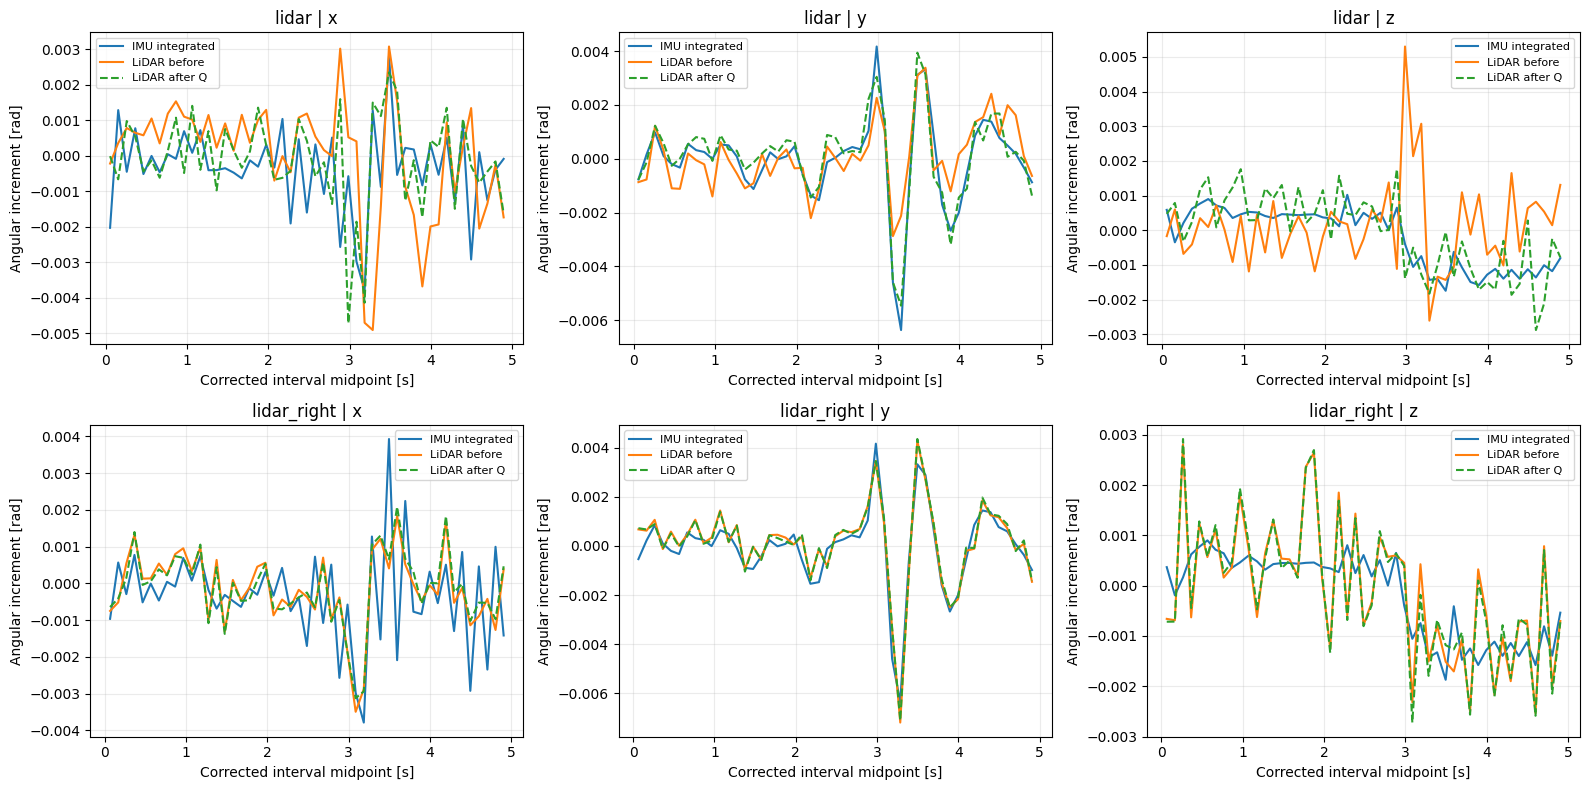

In [7]:
inspect_index = int(sweep_indices[INSPECT_EXAMPLE])
physical = get_physical(inspect_index)
inspect_cases = [make_case(INSPECT_SENSOR, INSPECT_ANGLE_DEG, INSPECT_TIME_MS, INSPECT_AXIS)]
inspect_window = faulted_window_from_cases(physical, inspect_cases)
with torch.no_grad():
    inspect_processed = process(inspect_window)
    ref_key, ref_name, sources = select_angular_streams(inspect_processed, inspect_window.streams, CALIBRATION_KEYS, wahba_config)
    inspect_pairs = solve_pairs(inspect_processed, inspect_window)
    inspect_numerical = numerical_extractor(inspect_processed, CALIBRATION_KEYS, raw_streams=inspect_window.streams)
    inspect_targets = correction_targets(physical, inspect_window, inspect_cases)
print('Sequence:', index_to_sequence[inspect_index], '| index:', inspect_index, '| reference:', ref_key, ref_name)
print('Processed streams:')
for name,s in inspect_processed.items():
    print(name, s.calibration_key, s.measurement_type, tuple(s.values.shape), 'valid samples:', int(s.sample_mask.sum()))
print('Numerical features:', inspect_numerical.values.shape, '| valid:', inspect_numerical.valid.tolist())
assert ref_key not in inspect_numerical.results and not inspect_numerical.values[:,REFERENCE_INDEX].any()
fig, axes = plt.subplots(len(SOURCE_KEYS), 3, figsize=(16, 4*len(SOURCE_KEYS)), squeeze=False)
for row,key in enumerate(SOURCE_KEYS):
    pairs = inspect_pairs[key]; result = inspect_numerical.results[key]; name = sources[key]
    assert pairs.reference_vectors.shape == pairs.source_vectors.shape
    mask = pairs.sample_mask[0]
    end = inspect_processed[name].timestamps[0]
    raw = inspect_window.streams[name]; duration = raw.timestamps[0]-raw.interval_start_timestamps[0]
    mid = end-duration/2
    a,b = pairs.reference_vectors[0,mask],pairs.source_vectors[0,mask]
    corrected = b @ result.rotation[0].T
    direct = solve_wahba(pairs.reference_vectors,pairs.source_vectors,pairs.sample_mask,pairs.weights,config=wahba_config)
    torch.testing.assert_close(direct.rotation,result.rotation)
    expected = inspect_targets[-2][0,CALIBRATION_KEYS.index(key)]
    print(f'\n{key}: raw gyro {tuple(inspect_processed[ref_name].values.shape)}, raw lidar log {tuple(inspect_processed[name].values.shape)} -> paired {tuple(pairs.reference_vectors.shape)}; valid={int(mask.sum())}/{mask.numel()}')
    print('Raw Wahba SO(3):\n', to_numpy(result.rotation[0]))
    print('True relative correction:\n', to_numpy(expected))
    print('Relative residual [deg]:', float(distance_so3_deg(result.rotation[0],expected)) if result.valid[0] else 'invalid')
    print('Raw features (before numerical MLP):', to_numpy(inspect_numerical.values[0,CALIBRATION_KEYS.index(key)]))
    print('Information eigenvalues:', to_numpy(result.eigenvalues[0]), '| RMS before/after [rad]:', float(result.residual_before[0]), float(result.residual_after[0]))
    display(pd.DataFrame(np.column_stack([to_numpy(mid[mask]),to_numpy(a),to_numpy(b),to_numpy(corrected)]),columns=['t_mid_s','imu_x','imu_y','imu_z','lidar_x','lidar_y','lidar_z','Q_lidar_x','Q_lidar_y','Q_lidar_z']).head(8))
    for j,component in enumerate('xyz'):
        ax = axes[row,j]; x = to_numpy(mid[mask]); ax.plot(x,to_numpy(a[:,j]),label='IMU integrated'); ax.plot(x,to_numpy(b[:,j]),label='LiDAR before'); ax.plot(x,to_numpy(corrected[:,j]),'--',label='LiDAR after Q'); ax.set(title=f'{key} | {component}',xlabel='Corrected interval midpoint [s]',ylabel='Angular increment [rad]'); ax.grid(alpha=.25); ax.legend(fontsize=8)
finish_figure(fig,'01_angular_correspondences.png')

## 7. Hybrid identity, routing and gradient checks on real tokens
Transfer **all** 002.27 parameters. Check exact parameter equality, raw numerical feature shapes, reference masking, initial feature equality and all output branches. Use normal tensors (not inference-mode tensors) for autograd. Do one temporary optimizer step on only the new layers, verify that the reference stays exactly zero, and restore the entire hybrid state. This is a smoke test, not training; the initialized model is restored even on failure.

In [8]:
baseline_model = hybrid_model = None
if RUN_HYBRID_CHECK:
    baseline_model = PooledCalibration6DModel(model_config).to(device=DEVICE,dtype=MODEL_DTYPE)
    load_training_checkpoint(CHECKPOINT_PATH,model=baseline_model,map_location=DEVICE)
    hybrid_model = PooledCalibrationHybridModel(hybrid_config).to(device=DEVICE,dtype=MODEL_DTYPE)
    hybrid_model.initialize_from_regressor(baseline_model)
    baseline_model.eval(); hybrid_model.eval(); hybrid_model.requires_grad_(True)
    for name,p in baseline_model.state_dict().items(): torch.testing.assert_close(p,hybrid_model.state_dict()[name],rtol=0.,atol=0.)
    # Several matched cases improve the chance of having a valid numerical pair.
    check_cases=[make_case(k,a,0.,INSPECT_AXIS) for k in CALIBRATION_KEYS for a in (0.,45.,150.)]
    check_window=faulted_window_from_cases(physical,check_cases)
    with torch.no_grad():
        check_streams=process(check_window)
        check_tokens=tokenizer(check_streams,calibration_keys=CALIBRATION_KEYS)
        check_num=numerical_extractor(check_streams,CALIBRATION_KEYS,raw_streams=check_window.streams)
        old=baseline_model(check_tokens); new=hybrid_model(check_tokens,numerical_features=check_num)
        disabled=hybrid_model(check_tokens,numerical_features=check_num,use_numerical=False)
        h,_=hybrid_model.encode_calibration_features(check_tokens,None)
        z=hybrid_model.encode_numerical_features(h,check_num,CALIBRATION_KEYS)
        fused=hybrid_model.feature_fusion(torch.cat((h,z),-1))
        print('Neural features:',h.shape,'raw numerical:',check_num.values.shape,'numerical embeddings:',z.shape,'fused:',fused.shape)
        assert not z.any()
        torch.testing.assert_close(fused,h,atol=3e-6,rtol=3e-6)
        identity_rows=[]
        for k in CALIBRATION_KEYS:
            a,b,c=old.predictions[k],new.predictions[k],disabled.predictions[k]
            for field in ('rotation_6d','delta_translation','delta_tau','delta_rotation'):
                torch.testing.assert_close(getattr(a,field),getattr(b,field),atol=1e-5,rtol=1e-5)
                torch.testing.assert_close(getattr(b,field),getattr(c,field),atol=1e-5,rtol=1e-5)
            identity_rows.append(dict(sensor=k,max_rotation_diff_deg=float(distance_so3_deg(a.delta_rotation,b.delta_rotation).max()),max_tau_diff_ms=float((a.delta_tau-b.delta_tau).abs().max()*1000)))
        display(pd.DataFrame(identity_rows))
    print('PASS: initialized hybrid reproduces 002.27, including the regression head.')
    if not check_num.valid.any():
        raise RuntimeError('No valid numerical pair in the inspection window. Choose another INSPECT_EXAMPLE for the real gradient check.')
    saved={k:v.detach().cpu().clone() for k,v in hybrid_model.state_dict().items()}
    try:
        optimizer=torch.optim.AdamW([*hybrid_model.numerical_encoder.parameters(),*hybrid_model.feature_fusion.parameters()],lr=3e-4,weight_decay=0.)
        hybrid_model.zero_grad(set_to_none=True)
        out=hybrid_model(check_tokens,numerical_features=check_num)
        C_target=correction_targets(physical,check_window,check_cases)[2]
        # Chordal loss only for a finite gradient smoke test, not a proposed training objective.
        loss=sum((out.predictions[k].delta_rotation-C_target[:,j]).square().mean() for j,k in enumerate(CALIBRATION_KEYS))
        loss.backward()
        def grad_norm(module):
            return sum(float(p.grad.detach().square().sum()) for p in module.parameters() if p.grad is not None)**.5
        grad_rows=[dict(module=name,grad_norm=grad_norm(module)) for name,module in [('numerical_encoder_first',hybrid_model.numerical_encoder.mlp[0]),('numerical_encoder_last',hybrid_model.numerical_encoder.mlp[-1]),('fusion',hybrid_model.feature_fusion),('head_6d',hybrid_model.head_6d)]]
        display(pd.DataFrame(grad_rows))
        assert grad_rows[1]['grad_norm'] > 0 and grad_rows[2]['grad_norm'] > 0 and grad_rows[3]['grad_norm'] > 0
        assert all(np.isfinite(r['grad_norm']) for r in grad_rows)
        optimizer.step()
        with torch.no_grad():
            z_after=hybrid_model.encode_numerical_features(h,check_num,CALIBRATION_KEYS)
            assert not z_after[:,REFERENCE_INDEX].any() and z_after[:,[CALIBRATION_KEYS.index(k) for k in SOURCE_KEYS]].abs().sum()>0
        hybrid_model.zero_grad(set_to_none=True)
        out=hybrid_model(check_tokens,numerical_features=check_num)
        sum((out.predictions[k].delta_rotation-C_target[:,j]).square().mean() for j,k in enumerate(CALIBRATION_KEYS)).backward()
        assert grad_norm(hybrid_model.numerical_encoder.mlp[0])>0
        print('PASS: numerical last layer learns on step 1; hidden layer receives gradients on step 2; reference remains exactly zero.')
    finally:
        hybrid_model.load_state_dict(saved,strict=True); hybrid_model.zero_grad(set_to_none=True); hybrid_model.eval()
        del saved,optimizer
    print('Restored original hybrid initialization. No checkpoint written.')

/home/camel/anaconda3/lib/python3.12/site-packages/torch/nn/modules/transformer.py:505: UserWarning: The PyTorch API of nested tensors is in prototype stage and will change in the near future. We recommend specifying layout=torch.jagged when constructing a nested tensor, as this layout receives active development, has better operator coverage, and works with torch.compile. (Triggered internally at /pytorch/aten/src/ATen/NestedTensorImpl.cpp:178.)
  output = torch._nested_tensor_from_mask(


Neural features: torch.Size([9, 3, 128]) raw numerical: torch.Size([9, 3, 18]) numerical embeddings: torch.Size([9, 3, 64]) fused: torch.Size([9, 3, 128])


,sensor,max_rotation_diff_deg,max_tau_diff_ms
0,imu,0.000005,0.000011
1,lidar,0.000005,0.000007
2,lidar_right,0.000019,0.000007


PASS: initialized hybrid reproduces 002.27, including the regression head.


,module,grad_norm
0,numerical_encoder_first,0.000000
1,numerical_encoder_last,0.000254
2,fusion,0.085621
3,head_6d,0.425135


PASS: numerical last layer learns on step 1; hidden layer receives gradients on step 2; reference remains exactly zero.
Restored original hybrid initialization. No checkpoint written.


## 8. Raw numerical sweep helpers
Every physical window is reused at all angles with the same sampled axes. A single fault is injected into each sensor in turn, including the reference IMU. Raw numerical solutions are evaluated **against relative ground truth**. For a reference fault, both LiDAR relative targets are nonzero. For non-reference faults, only the corresponding pair target is nonzero.

Invalid numerical estimates are kept in the CSV but excluded from numerical error summaries; validity rate is always reported. Rank-deficient nonstatic estimates remain valid and are included. The optional absolute diagnostic uses the SO(3) medoid of `[I,Q_left,Q_right]`, with all pairs valid; the oracle-gauge diagnostic uses GT IMU correction and is not deployable. Neither is used by the hybrid.

In [9]:
@torch.no_grad()
def numerical_case_rows(physical, cases, index):
    window = faulted_window_from_cases(physical, cases)
    streams = process(window)
    numerical = numerical_extractor(streams, CALIBRATION_KEYS, raw_streams=window.streams)
    assert numerical.reference_key == REFERENCE_KEY and set(numerical.results) == set(SOURCE_KEYS)
    R_prior,R_true,C_true,c_true,Q_true,q_true = correction_targets(physical,window,cases)
    B = len(cases); eye = torch.eye(3,device=DEVICE,dtype=MODEL_DTYPE).expand(B,3,3)
    Q = torch.stack([eye if k == REFERENCE_KEY else numerical.results[k].rotation for k in CALIBRATION_KEYS],1)
    all_valid = numerical.valid[:,[CALIBRATION_KEYS.index(k) for k in SOURCE_KEYS]].all(1)
    C_medoid, _, medoid_idx = recover_absolute_corrections(Q, torch.zeros_like(c_true))
    C_oracle = C_true[:,REFERENCE_INDEX:REFERENCE_INDEX+1] @ Q
    relative_error = distance_so3_deg(Q,Q_true)
    rel_mag = distance_so3_deg(Q,eye[:,None]); target_mag = distance_so3_deg(Q_true,eye[:,None])
    abs_error = distance_so3_deg(C_medoid @ R_prior,R_true)
    abs_mag = distance_so3_deg(C_medoid,eye[:,None]); oracle_error = distance_so3_deg(C_oracle @ R_prior,R_true)
    init_error = distance_so3_deg(R_prior,R_true)
    common = torch.stack([rel_mag,target_mag,relative_error,abs_error,abs_mag,oracle_error,init_error],-1).cpu().numpy()
    valid_all = to_numpy(all_valid); medoids = to_numpy(medoid_idx)
    diagnostics = {}
    for k,r in numerical.results.items():
        eig = r.eigenvalues; ratio = eig[:,0] / eig[:,-1].clamp_min(torch.finfo(eig.dtype).tiny)
        diagnostics[k] = dict(valid=to_numpy(r.valid), count=to_numpy(r.num_correspondences), before=to_numpy(r.residual_before), after=to_numpy(r.residual_after), energy=to_numpy(r.motion_energy), eig=to_numpy(eig), ratio=to_numpy(ratio), rotation=to_numpy(r.rotation))
    rows=[]
    for b,case in enumerate(cases):
        for j,key in enumerate(CALIBRATION_KEYS):
            rel_pred,rel_gt,rel_error,abs_err,abs_pred,oracle,init = common[b,j]
            d=diagnostics.get(key); valid = bool(d['valid'][b]) if d else False
            row=dict(sequence=index_to_sequence[int(index)],physical_index=int(index),selected_sensor=case['selected_sensor'],angle_deg=case['angle_deg'],injected_tau_ms=case['injected_tau_ms'],axis_id=case['axis_id'],sensor=key,
                valid=valid,all_pairs_valid=bool(valid_all[b]),relative_target_deg=float(rel_gt) if d else np.nan,relative_correction_deg=float(rel_pred) if valid else np.nan,relative_error_deg=float(rel_error) if valid else np.nan,
                initial_error_deg=float(init),absolute_correction_deg=float(abs_pred) if valid_all[b] else np.nan,absolute_residual_deg=float(abs_err) if valid_all[b] else np.nan,oracle_residual_deg=float(oracle) if valid else np.nan,medoid_key=CALIBRATION_KEYS[medoids[b]] if valid_all[b] else None)
            if d:
                row.update(num_correspondences=int(d['count'][b]),residual_before_rad=float(d['before'][b]),residual_after_rad=float(d['after'][b]),motion_energy_rad2=float(d['energy'][b]),eig_min=float(d['eig'][b,0]),eig_mid=float(d['eig'][b,1]),eig_max=float(d['eig'][b,2]),eig_ratio=float(d['ratio'][b]))
                row.update({f'Q_{u}{v}': float(d['rotation'][b,u,v]) for u in range(3) for v in range(3)})
            rows.append(row)
    return rows


def run_numerical_sweep(indices, angles, time_offsets, label):
    rows=[]; start=time.perf_counter()
    for i,index in enumerate(indices):
        physical = get_physical(index)
        rng = np.random.default_rng(RANDOM_SEED+100003+int(index))
        axes = {(sensor,axis_id):rng.normal(size=3) for sensor in CALIBRATION_KEYS for axis_id in range(SWEEP_AXIS_REPEATS)}
        cases = [make_case(sensor, angle, tau, axes[sensor,axis_id],axis_id) for sensor in CALIBRATION_KEYS for axis_id in range(SWEEP_AXIS_REPEATS) for angle in angles for tau in time_offsets]
        for offset in range(0,len(cases),BATCH_SIZE):
            rows.extend(numerical_case_rows(physical,cases[offset:offset+BATCH_SIZE],index))
        if (i+1)%8 == 0 or i+1 == len(indices): print(f'{label}: {i+1}/{len(indices)} windows | {time.perf_counter()-start:.1f} s')
    df=pd.DataFrame(rows)
    assert not df.duplicated(['physical_index','selected_sensor','angle_deg','injected_tau_ms','axis_id','sensor']).any()
    df.to_csv(RUN_DIR / f'{EVAL_SPLIT}_{label}_raw.csv',index=False)
    return df


def quantile_curve(ax, df, x, y, label, *, band=True):
    stats = df.groupby(x)[y].agg(median='median',p10=lambda a:a.quantile(.1),p90=lambda a:a.quantile(.9)).sort_index()
    xx = stats.index.to_numpy(dtype=float); yy=stats['median'].to_numpy(dtype=float)
    line,=ax.plot(xx,yy,'-o',label=label,markersize=3)
    if band: ax.fill_between(xx,stats.p10.to_numpy(dtype=float),stats.p90.to_numpy(dtype=float),color=line.get_color(),alpha=.12)
    ax.grid(alpha=.25)


def numerical_summary(df, x):
    pairs=df[df.sensor.isin(SOURCE_KEYS)].copy()
    for field in ('residual_before_rad','residual_after_rad','eig_ratio'):
        pairs.loc[~pairs.valid,field]=np.nan
    return pairs.groupby(['selected_sensor','sensor',x],as_index=False).agg(n=('valid','size'),n_valid=('valid','sum'),valid_rate=('valid','mean'),relative_median_deg=('relative_error_deg','median'),relative_mae_deg=('relative_error_deg','mean'),relative_p90_deg=('relative_error_deg',lambda s:s.quantile(.9)),fit_before_rad=('residual_before_rad','median'),fit_after_rad=('residual_after_rad','median'),median_eig_ratio=('eig_ratio','median'))

## 9. Rotation sweep: 0–179°
Each nonzero angle has `SWEEP_WINDOWS_PER_SEQUENCE × number of sequences × SWEEP_AXIS_REPEATS` cases per injected sensor (96 by default, if all windows available). Zero-angle controls are repeated for matched axes/sensors, not independent new physical data. Plot medians and P10–P90 across individual cases. The numerical validity rate is plotted separately.

For fixed angular correspondences and sufficiently informative motion, pure prior rotations change the coordinate system of the Wahba problem but not its attainable fit or relative geodesic error. Therefore nearly flat relative-error curves are **expected**, not necessarily a problem. Rank deficiency, noise, finite precision and SVD tie-breaking can break this behavior.

rotation: 8/48 windows | 4.9 s
rotation: 16/48 windows | 10.1 s
rotation: 24/48 windows | 15.0 s
rotation: 32/48 windows | 19.7 s
rotation: 40/48 windows | 24.5 s
rotation: 48/48 windows | 29.3 s


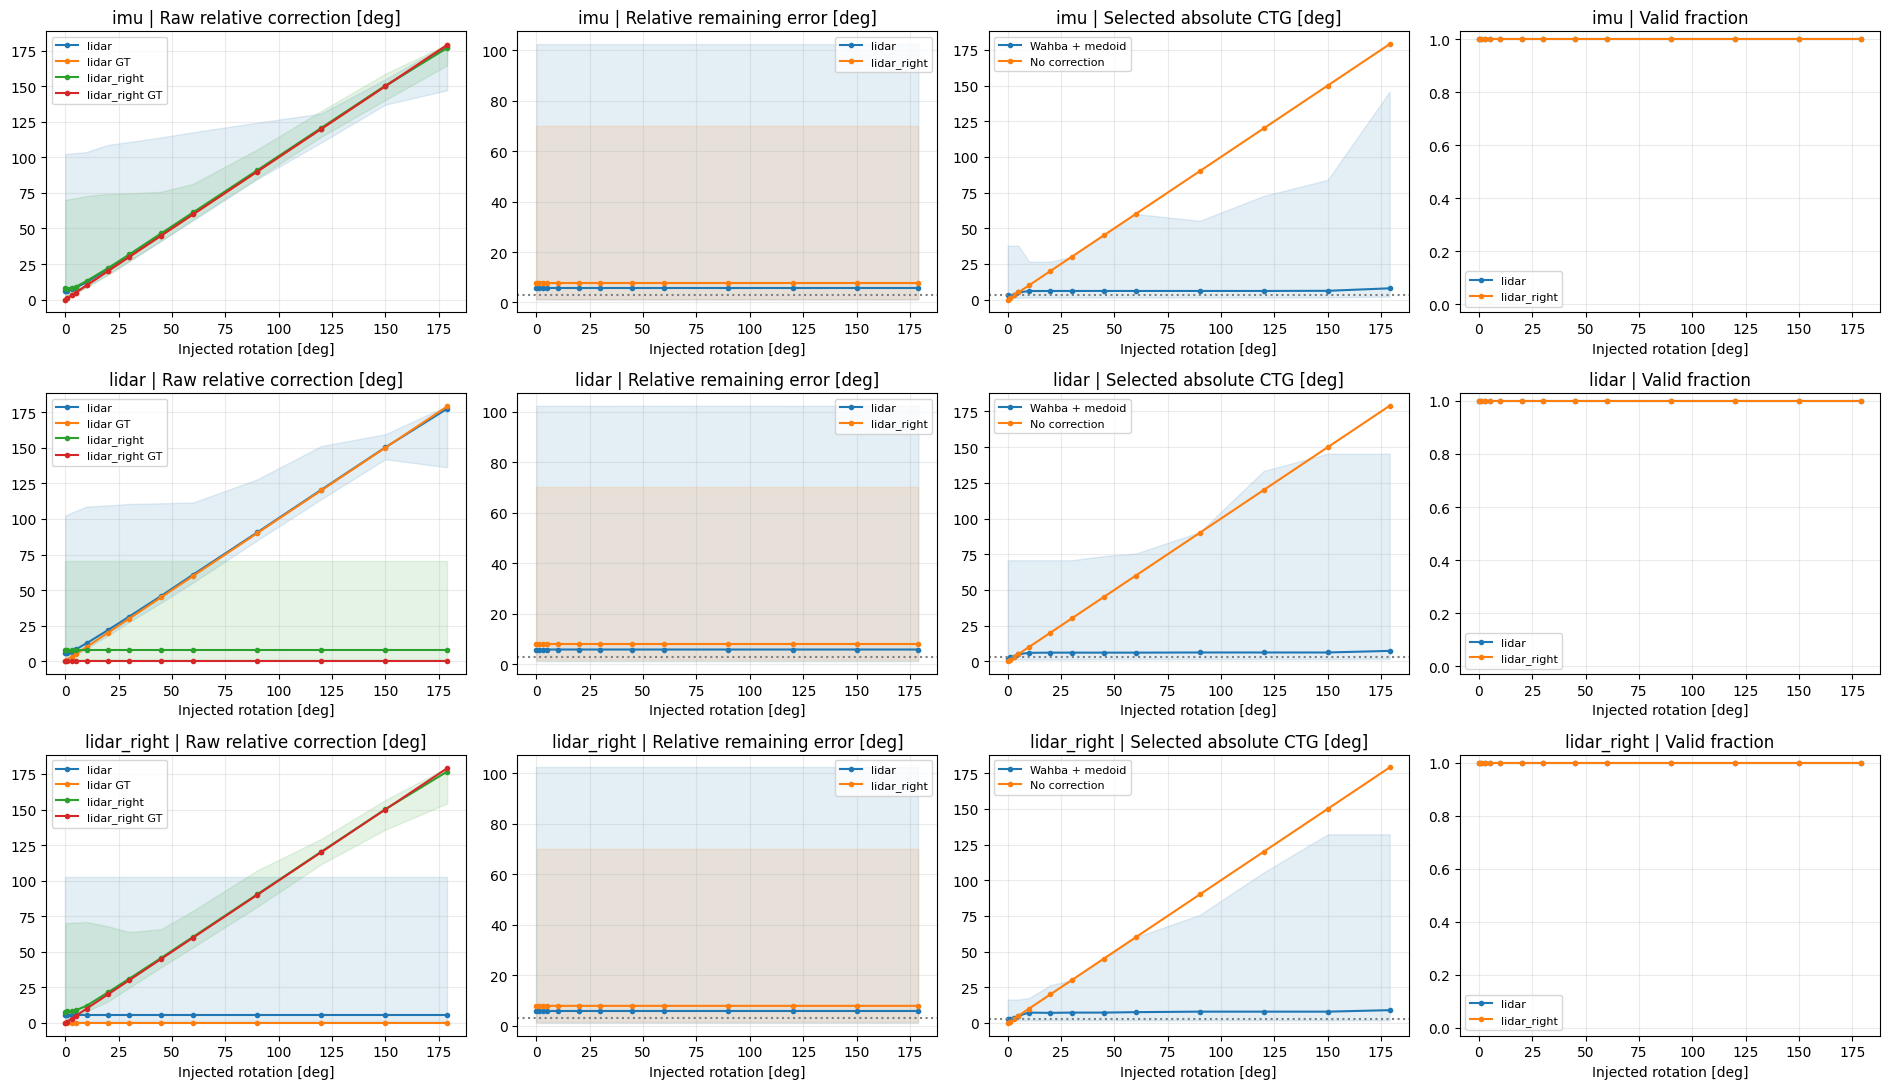

,selected_sensor,sensor,angle_deg,n,n_valid,valid_rate,relative_median_deg,relative_mae_deg,relative_p90_deg,fit_before_rad,fit_after_rad,median_eig_ratio
0,imu,lidar,0.0,96,96,1.0,5.8029,26.0917,102.3494,0.0022,0.0021,0.3223
9,imu,lidar,90.0,96,96,1.0,5.8029,26.0918,102.3493,0.0043,0.0021,0.3223
11,imu,lidar,150.0,96,96,1.0,5.8029,26.0918,102.3493,0.0053,0.0021,0.3223
12,imu,lidar,179.0,96,96,1.0,5.8029,26.0917,102.3493,0.0055,0.0021,0.3223
13,imu,lidar_right,0.0,96,96,1.0,7.9152,20.8635,70.1016,0.0022,0.0022,0.3145
22,imu,lidar_right,90.0,96,96,1.0,7.9152,20.8635,70.1016,0.0040,0.0022,0.3145
24,imu,lidar_right,150.0,96,96,1.0,7.9152,20.8635,70.1016,0.0051,0.0022,0.3145
25,imu,lidar_right,179.0,96,96,1.0,7.9152,20.8635,70.1016,0.0053,0.0022,0.3145
26,lidar,lidar,0.0,96,96,1.0,5.8029,26.0917,102.3494,0.0022,0.0021,0.3223
35,lidar,lidar,90.0,96,96,1.0,5.8029,26.0916,102.3426,0.0043,0.0021,0.3223


,selected_sensor,angle_deg,n,valid_rate,correction_median_deg,residual_median_deg,residual_p90_deg
0,imu,0.0,96,1.0,2.961,2.961,37.789
9,imu,90.0,96,1.0,89.038,6.063,55.189
11,imu,150.0,96,1.0,148.398,6.163,83.920
12,imu,179.0,96,1.0,175.630,7.915,145.750
13,lidar,0.0,96,1.0,1.791,1.791,70.771
22,lidar,90.0,96,1.0,89.193,6.163,90.461
24,lidar,150.0,96,1.0,148.620,6.163,145.440
25,lidar,179.0,96,1.0,175.213,7.282,145.443
26,lidar_right,0.0,96,1.0,3.053,3.053,16.409
35,lidar_right,90.0,96,1.0,89.165,7.915,75.693


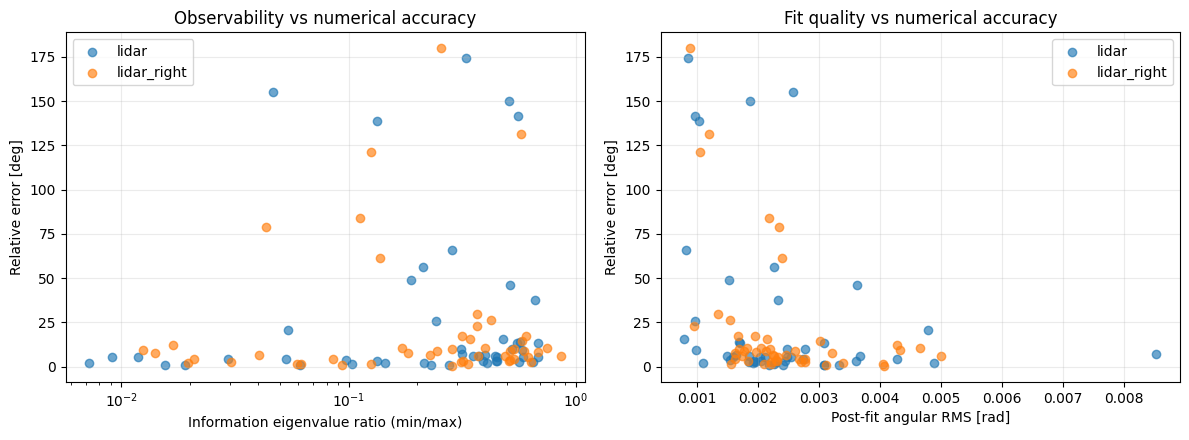

In [10]:
if RUN_ROTATION_SWEEP:
    rotation_df = run_numerical_sweep(sweep_indices,SWEEP_ANGLES_DEG,(0.,),'rotation')
    rotation_summary = numerical_summary(rotation_df,'angle_deg')
    rotation_summary.to_csv(RUN_DIR / f'{EVAL_SPLIT}_rotation_summary.csv',index=False)
    fig,axes=plt.subplots(3,4,figsize=(19,11),squeeze=False)
    for row,selected in enumerate(CALIBRATION_KEYS):
        d=rotation_df[rotation_df.selected_sensor==selected]
        for key in SOURCE_KEYS:
            g=d[d.sensor==key]
            quantile_curve(axes[row,0],g,'angle_deg','relative_correction_deg',key)
            quantile_curve(axes[row,0],g,'angle_deg','relative_target_deg',key+' GT',band=False)
            quantile_curve(axes[row,1],g,'angle_deg','relative_error_deg',key)
            axes[row,3].plot(g.groupby('angle_deg').valid.mean(),'-o',label=key,markersize=3)
        g=d[d.sensor==selected]
        quantile_curve(axes[row,2],g,'angle_deg','absolute_residual_deg','Wahba + medoid')
        quantile_curve(axes[row,2],g,'angle_deg','initial_error_deg','No correction',band=False)
        for col,title in enumerate(('Raw relative correction [deg]','Relative remaining error [deg]','Selected absolute CTG [deg]','Valid fraction')):
            ax=axes[row,col]; ax.set(title=f'{selected} | {title}',xlabel='Injected rotation [deg]'); ax.grid(alpha=.25); ax.legend(fontsize=8)
        axes[row,3].set_ylim(-.03,1.03)
        axes[row,1].axhline(GT_ROT_TOL_DEG,color='gray',ls=':')
        axes[row,2].axhline(GT_ROT_TOL_DEG,color='gray',ls=':')
    finish_figure(fig,'02_rotation_sweep.png')
    display(rotation_summary[rotation_summary.angle_deg.isin([0.,90.,150.,179.])].round(4))
    selected_df=rotation_df[rotation_df.sensor==rotation_df.selected_sensor]
    absolute_summary=selected_df.groupby(['selected_sensor','angle_deg'],as_index=False).agg(n=('all_pairs_valid','size'),valid_rate=('all_pairs_valid','mean'),correction_median_deg=('absolute_correction_deg','median'),residual_median_deg=('absolute_residual_deg','median'),residual_p90_deg=('absolute_residual_deg',lambda a:a.quantile(.9)))
    absolute_summary.to_csv(RUN_DIR / f'{EVAL_SPLIT}_rotation_absolute_summary.csv',index=False)
    display(absolute_summary[absolute_summary.angle_deg.isin([0.,90.,150.,179.])].round(3))
    # Information vs accuracy: one zero-rotation case per physical window and pair.
    clean=rotation_df[(rotation_df.angle_deg==0.) & (rotation_df.sensor.isin(SOURCE_KEYS)) & rotation_df.valid].drop_duplicates(['physical_index','sensor'])
    fig,axes=plt.subplots(1,2,figsize=(12,4.5))
    for key in SOURCE_KEYS:
        g=clean[clean.sensor==key]
        axes[0].scatter(g.eig_ratio.clip(lower=1e-10),g.relative_error_deg,label=key,alpha=.65)
        axes[1].scatter(g.residual_after_rad,g.relative_error_deg,label=key,alpha=.65)
    axes[0].set(xlabel='Information eigenvalue ratio (min/max)',ylabel='Relative error [deg]',xscale='log',title='Observability vs numerical accuracy')
    axes[1].set(xlabel='Post-fit angular RMS [rad]',ylabel='Relative error [deg]',title='Fit quality vs numerical accuracy')
    for ax in axes: ax.grid(alpha=.25); ax.legend()
    finish_figure(fig,'02b_observability_vs_accuracy.png')


## 10. Time-offset sensitivity (no time-offset solver)
Perturb the supplied prior time offset, alone or together with a rotation of the same sensor. A wrong temporal prior changes correspondences, so numerical rotation and fit quality may deteriorate. This is a diagnostic, not a lag search or a time-calibration algorithm.

time: 8/24 windows | 9.5 s
time: 16/24 windows | 18.4 s
time: 24/24 windows | 27.0 s


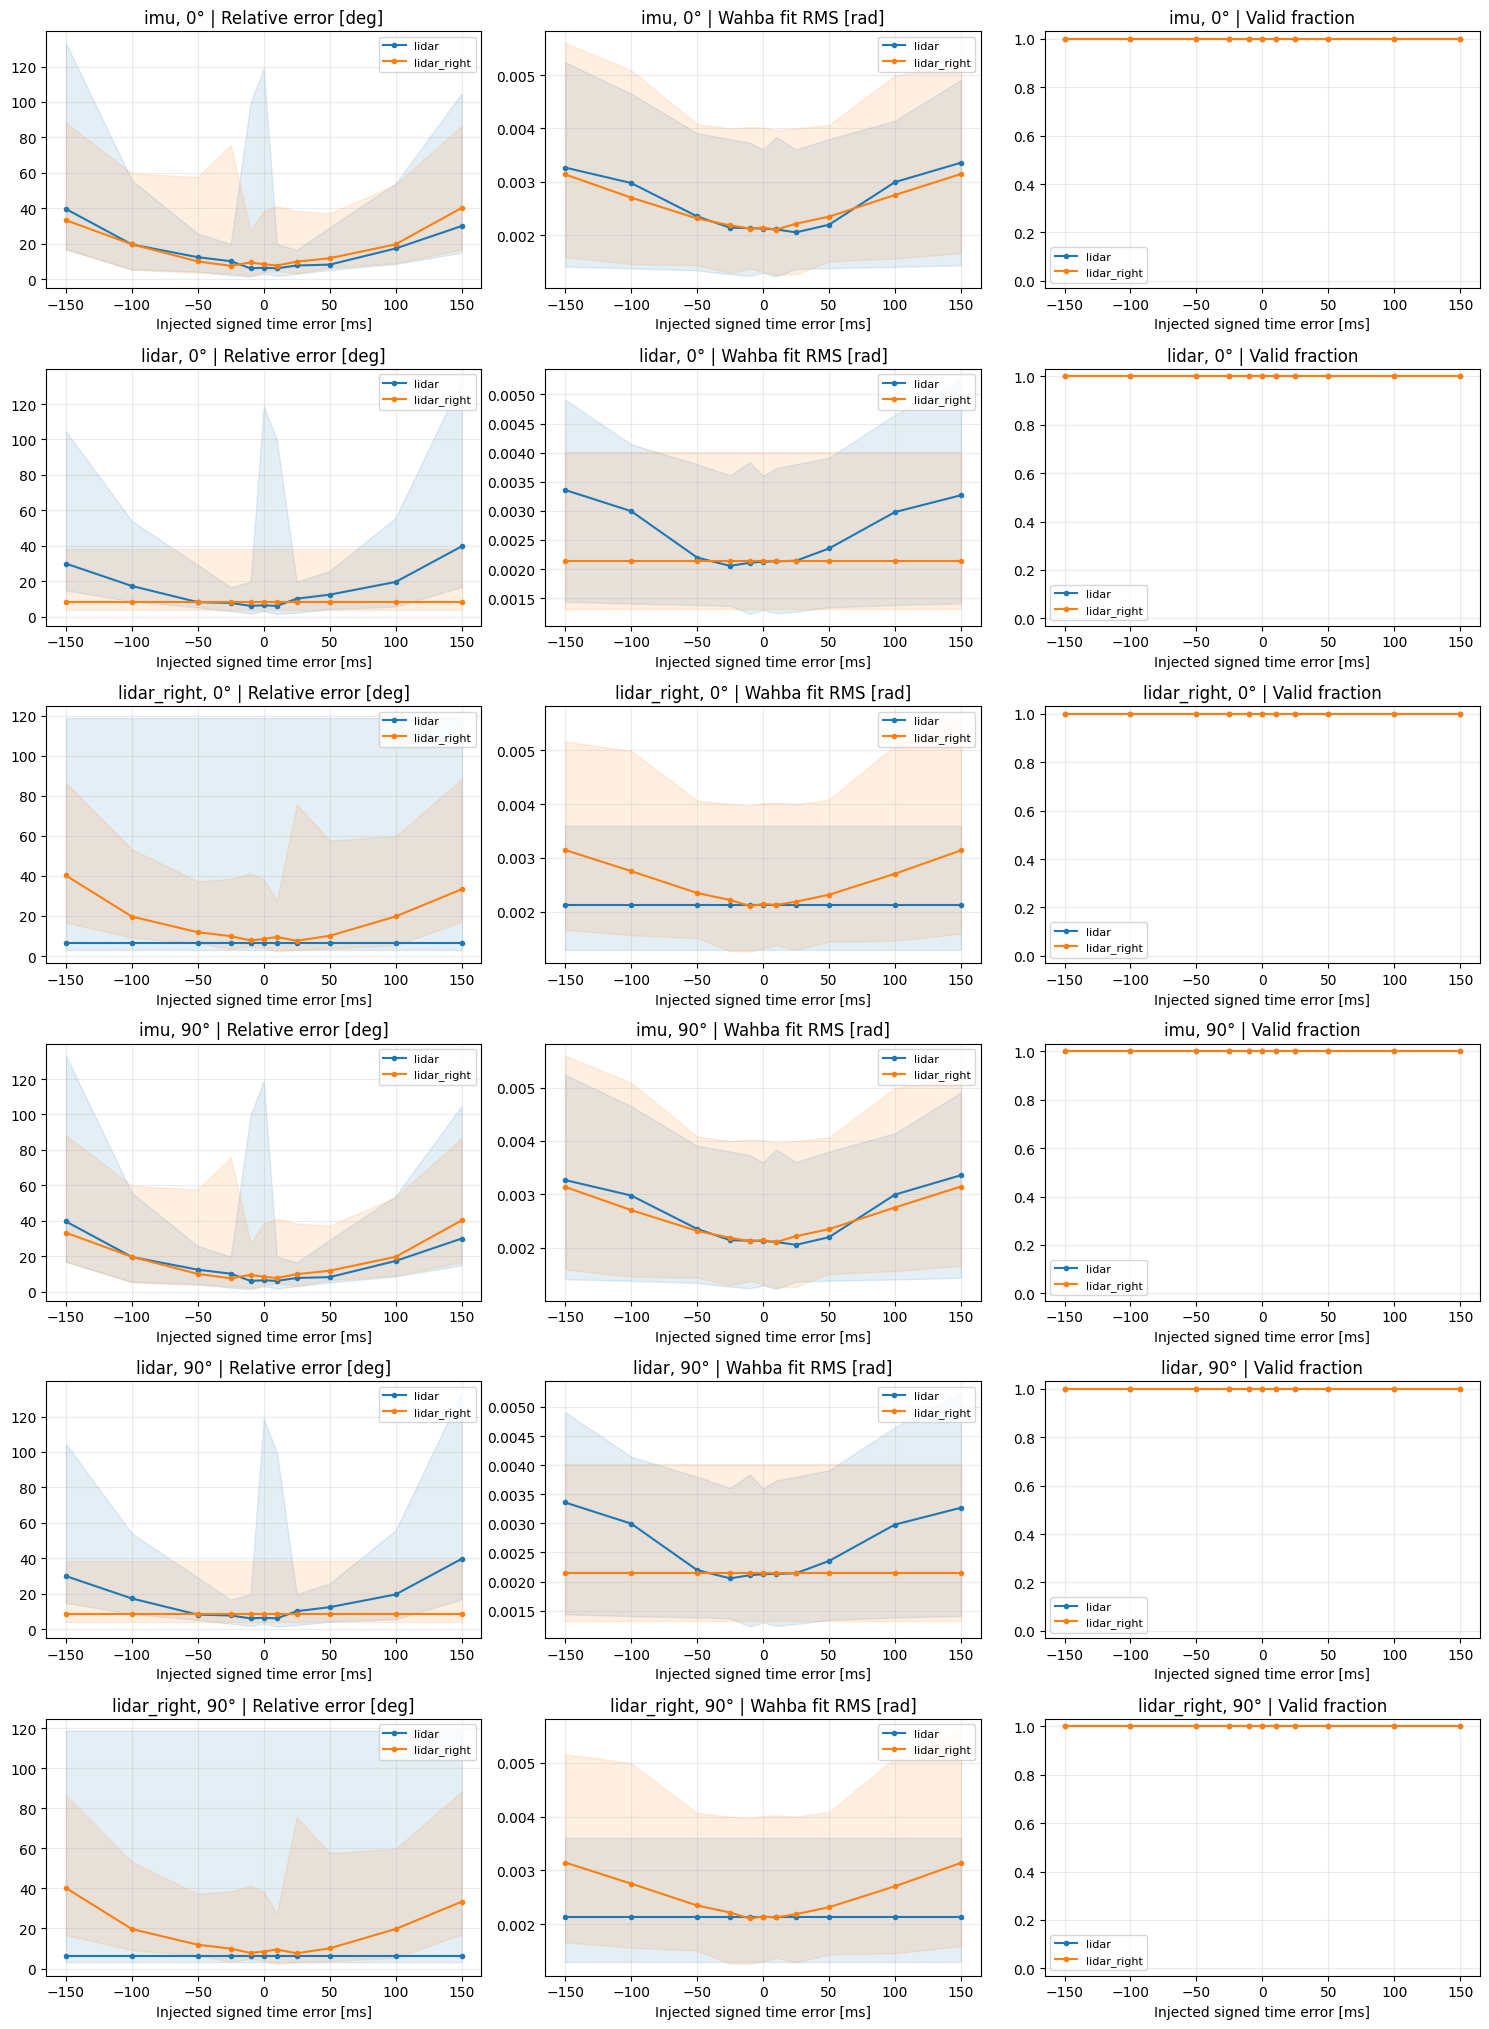

,selected_sensor,sensor,injected_tau_ms,n,n_valid,valid_rate,relative_median_deg,relative_mae_deg,relative_p90_deg,fit_before_rad,fit_after_rad,median_eig_ratio,angle_deg
0,imu,lidar,-150.0,48,48,1.0,39.6898,56.9842,133.2560,0.0035,0.0033,0.5044,0.0
5,imu,lidar,0.0,48,48,1.0,6.4944,25.0877,118.8611,0.0021,0.0021,0.4982,0.0
10,imu,lidar,150.0,48,48,1.0,30.0145,49.1816,104.6858,0.0034,0.0034,0.4922,0.0
11,imu,lidar_right,-150.0,48,48,1.0,33.3344,45.7450,88.3151,0.0034,0.0031,0.4195,0.0
16,imu,lidar_right,0.0,48,48,1.0,8.5023,23.6257,38.4967,0.0022,0.0021,0.4116,0.0
21,imu,lidar_right,150.0,48,48,1.0,40.2290,48.7503,86.5251,0.0033,0.0031,0.4106,0.0
22,lidar,lidar,-150.0,48,48,1.0,30.0144,49.1816,104.6863,0.0034,0.0034,0.4922,0.0
27,lidar,lidar,0.0,48,48,1.0,6.4944,25.0877,118.8611,0.0021,0.0021,0.4982,0.0
32,lidar,lidar,150.0,48,48,1.0,39.6902,56.9842,133.2562,0.0035,0.0033,0.5044,0.0
33,lidar,lidar_right,-150.0,48,48,1.0,8.5023,23.6257,38.4967,0.0022,0.0021,0.4116,0.0


In [11]:
if RUN_TIME_SWEEP:
    time_indices=np.concatenate([select_spread_indices_by_names(eval_dataset,(seq,),TIME_SWEEP_WINDOWS_PER_SEQUENCE,RANDOM_SEED+51+i) for i,seq in enumerate(EVAL_NAMES)])
    time_df=run_numerical_sweep(time_indices,TIME_SWEEP_ROTATION_DEG,TIME_SWEEP_MS,'time')
    fig,axes=plt.subplots(len(TIME_SWEEP_ROTATION_DEG)*3,3,figsize=(15,3.4*len(TIME_SWEEP_ROTATION_DEG)*3),squeeze=False)
    for i,angle in enumerate(TIME_SWEEP_ROTATION_DEG):
        for j,selected in enumerate(CALIBRATION_KEYS):
            row=i*3+j; d=time_df[(time_df.angle_deg==angle)&(time_df.selected_sensor==selected)]
            for key in SOURCE_KEYS:
                g=d[d.sensor==key]; good=g[g.valid]
                quantile_curve(axes[row,0],g,'injected_tau_ms','relative_error_deg',key)
                quantile_curve(axes[row,1],good,'injected_tau_ms','residual_after_rad',key)
                axes[row,2].plot(g.groupby('injected_tau_ms').valid.mean(),'-o',label=key,markersize=3)
            for col,title in enumerate(('Relative error [deg]','Wahba fit RMS [rad]','Valid fraction')):
                ax=axes[row,col]; ax.set(title=f'{selected}, {angle:g}° | {title}',xlabel='Injected signed time error [ms]'); ax.grid(alpha=.25); ax.legend(fontsize=8)
            axes[row,2].set_ylim(-.03,1.03)
    finish_figure(fig,'03_time_sensitivity.png')
    time_summary=pd.concat([numerical_summary(g,'injected_tau_ms').assign(angle_deg=angle) for angle,g in time_df.groupby('angle_deg')],ignore_index=True)
    time_summary.to_csv(RUN_DIR / f'{EVAL_SPLIT}_time_summary.csv',index=False)
    display(time_summary[time_summary.injected_tau_ms.isin([-150.,0.,150.])].round(4))

## 11. Runtime: correspondence construction vs SVD vs entire numerical branch
Warmup and synchronize CUDA before/after each measurement. Report median and P90 wall-clock latency, milliseconds per calibration case, and for pairwise stages milliseconds per pair. Timing excludes dataset loading, augmentation and fault construction. A batch repeats one physical window with varied priors to isolate batch-size scaling; it is not a throughput benchmark on mixed-length real batches. Solver timing includes covariance, SVD, determinant correction, information and residual calculations, not just `torch.linalg.svd`. Each full feature extraction includes pairing, both solves and feature conversion. Full pipeline latency includes geometry, tokenization, numerical branch where applicable and forward, but not data loading or backward. Stage timings are measured independently and need not sum exactly.

B=  1 | geometry                   median=   7.305 ms | P90=  17.405 ms | per case=   7.305 ms
B=  1 | tokenization               median=   1.101 ms | P90=   1.333 ms | per case=   1.101 ms
B=  1 | angular_correspondences    median=   9.535 ms | P90=  17.487 ms | per case=   9.535 ms
B=  1 | wahba_solve_both           median=   6.900 ms | P90=   9.818 ms | per case=   6.900 ms
B=  1 | encode_raw_wahba_features  median=   1.042 ms | P90=   1.370 ms | per case=   1.042 ms
B=  1 | numerical_total            median=  12.549 ms | P90=  15.090 ms | per case=  12.549 ms
B=  1 | baseline_forward           median=  18.109 ms | P90=  23.229 ms | per case=  18.109 ms
B=  1 | hybrid_forward             median=  26.177 ms | P90=  41.042 ms | per case=  26.177 ms
B=  1 | baseline_pipeline          median=  28.729 ms | P90=  41.433 ms | per case=  28.729 ms
B=  1 | hybrid_pipeline            median=  52.045 ms | P90=  80.238 ms | per case=  52.045 ms
B=  8 | geometry                   median=  10.820

,batch_size,stage,median_ms,p90_ms,ms_per_case,ms_per_pair,device,valid_pairs
0,1,geometry,7.3047,17.4049,7.3047,NaN,cuda,2
1,1,tokenization,1.1015,1.3328,1.1015,NaN,cuda,2
2,1,angular_correspondences,9.5351,17.4870,9.5351,4.7675,cuda,2
3,1,wahba_solve_both,6.8997,9.8182,6.8997,3.4498,cuda,2
4,1,encode_raw_wahba_features,1.0420,1.3702,1.0420,0.5210,cuda,2
5,1,numerical_total,12.5490,15.0900,12.5490,6.2745,cuda,2
6,1,baseline_forward,18.1086,23.2286,18.1086,NaN,cuda,2
7,1,hybrid_forward,26.1773,41.0417,26.1773,NaN,cuda,2
8,1,baseline_pipeline,28.7287,41.4327,28.7287,NaN,cuda,2
9,1,hybrid_pipeline,52.0451,80.2379,52.0451,NaN,cuda,2


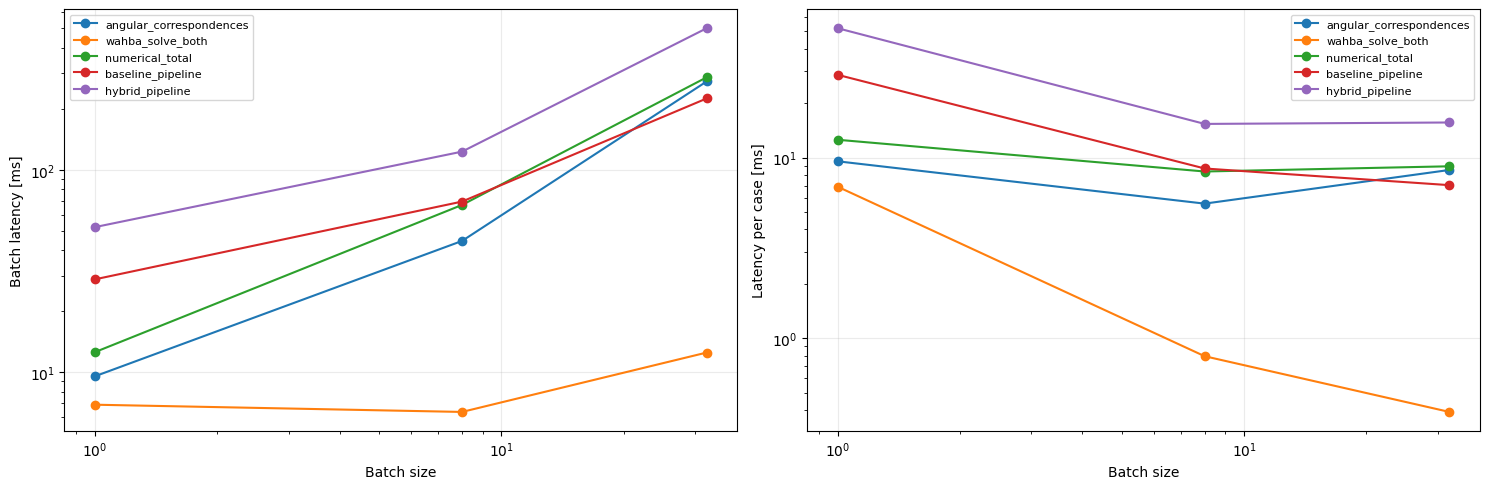

,baseline_ms,hybrid_ms,extra_ms,ratio
batch_size,,,,
1,28.729,52.045,23.316,1.812
8,69.600,122.854,53.254,1.765
32,225.109,500.447,275.338,2.223


In [12]:
def synchronize():
    if DEVICE.type=='cuda': torch.cuda.synchronize(DEVICE)


def benchmark(fn):
    for _ in range(TIMING_WARMUP): fn()
    synchronize(); elapsed=[]
    for _ in range(TIMING_REPEATS):
        synchronize(); start=time.perf_counter(); fn(); synchronize(); elapsed.append((time.perf_counter()-start)*1000.)
    return float(np.median(elapsed)),float(np.quantile(elapsed,.9))


@torch.no_grad()
def benchmark_all():
    rows=[]
    for size in TIMING_BATCH_SIZES:
        rng=np.random.default_rng(RANDOM_SEED+size)
        cases=[make_case(CALIBRATION_KEYS[i%3],float(rng.uniform(0.,179.)),0.,rng.normal(size=3)) for i in range(size)]
        w=faulted_window_from_cases(physical,cases); streams=process(w)
        pairs=solve_pairs(streams,w)
        numerical=numerical_extractor(streams,CALIBRATION_KEYS,raw_streams=w.streams)
        tokens=tokenizer(streams,calibration_keys=CALIBRATION_KEYS)
        def solve_only():
            return {k:solve_wahba(p.reference_vectors,p.source_vectors,p.sample_mask,p.weights,config=wahba_config) for k,p in pairs.items()}
        results=solve_only()
        def full_baseline():
            s=process(w); return baseline_model(tokenizer(s,calibration_keys=CALIBRATION_KEYS))
        def full_hybrid():
            s=process(w); t=tokenizer(s,calibration_keys=CALIBRATION_KEYS); n=numerical_extractor(s,CALIBRATION_KEYS,raw_streams=w.streams); return hybrid_model(t,numerical_features=n)
        stages=[('geometry',lambda:process(w),False),('tokenization',lambda:tokenizer(streams,calibration_keys=CALIBRATION_KEYS),False),('angular_correspondences',lambda:solve_pairs(streams,w),True),('wahba_solve_both',solve_only,True),('encode_raw_wahba_features',lambda:[encode_wahba_result(r,feature_config) for r in results.values()],True),('numerical_total',lambda:numerical_extractor(streams,CALIBRATION_KEYS,raw_streams=w.streams),True)]
        if baseline_model is not None and hybrid_model is not None:
            stages.extend([('baseline_forward',lambda:baseline_model(tokens),False),('hybrid_forward',lambda:hybrid_model(tokens,numerical_features=numerical),False),('baseline_pipeline',full_baseline,False),('hybrid_pipeline',full_hybrid,False)])
        for name,fn,pair_stage in stages:
            med,p90=benchmark(fn)
            rows.append(dict(batch_size=size,stage=name,median_ms=med,p90_ms=p90,ms_per_case=med/size,ms_per_pair=med/(size*len(SOURCE_KEYS)) if pair_stage else np.nan,device=str(DEVICE),valid_pairs=int(numerical.valid.sum())))
            print(f'B={size:3d} | {name:26s} median={med:8.3f} ms | P90={p90:8.3f} ms | per case={med/size:8.3f} ms')
    return pd.DataFrame(rows)

if RUN_TIMING:
    timing_df=benchmark_all()
    timing_df.to_csv(RUN_DIR / f'{EVAL_SPLIT}_timing.csv',index=False)
    display(timing_df.round(4))
    fig,axes=plt.subplots(1,2,figsize=(15,5))
    for name in ('angular_correspondences','wahba_solve_both','numerical_total','baseline_pipeline','hybrid_pipeline'):
        g=timing_df[timing_df.stage==name].sort_values('batch_size')
        if len(g):
            axes[0].plot(g.batch_size,g.median_ms,'-o',label=name); axes[1].plot(g.batch_size,g.ms_per_case,'-o',label=name)
    for ax,y in zip(axes,('Batch latency [ms]','Latency per case [ms]')):
        ax.set(xlabel='Batch size',ylabel=y,xscale='log',yscale='log'); ax.grid(alpha=.25); ax.legend(fontsize=8)
    finish_figure(fig,'04_runtime.png')
    if 'hybrid_pipeline' in timing_df.stage.values:
        latency=timing_df.pivot(index='batch_size',columns='stage',values='median_ms')
        display(pd.DataFrame({'baseline_ms':latency.baseline_pipeline,'hybrid_ms':latency.hybrid_pipeline,'extra_ms':latency.hybrid_pipeline-latency.baseline_pipeline,'ratio':latency.hybrid_pipeline/latency.baseline_pipeline}).round(3))

## 12. Interpretation
- Inspect the raw SO(3) solutions first. Relative error is the correct metric even when IMU is faulty. Medoid absolute CTG is a separate, sparse-fault diagnostic, not a property of the learned hybrid.
- Low fit residual does not imply correct rotation: compare the information eigenvalues and GT error. The `valid` flag is not a full-observability flag.
- Time perturbations intentionally alter correspondence quality. No independent synchronization is performed.
- Exact initialization and nonzero numerical gradients are necessary checks, not evidence that trained fusion will improve calibration. The initial hidden encoder gradient is expected to be zero until the final numerical layer learns.
- Benchmark the real numerical branch before choosing training batch size. Correspondence construction can dominate the small 3×3 SVD; the current implementation loops over batch rows and constructs interval-overlap arrays.
- This notebook does not fit or save new model weights.

In [13]:
settings=dict(split=EVAL_SPLIT, sequences=list(EVAL_NAMES), seed=RANDOM_SEED, physical_augmentation=ENABLE_PHYSICAL_AUGMENTATION, rotation_angles=list(SWEEP_ANGLES_DEG), axis_repeats=SWEEP_AXIS_REPEATS, rotation_indices=sweep_indices.tolist(), time_offsets_ms=list(TIME_SWEEP_MS), time_angles=list(TIME_SWEEP_ROTATION_DEG), device=str(DEVICE), dtype=str(MODEL_DTYPE), checkpoint=str(CHECKPOINT_PATH), wahba_config=vars(wahba_config), feature_config=vars(feature_config), timing_batch_sizes=list(TIMING_BATCH_SIZES), timing_repeats=TIMING_REPEATS)
if RUN_TIME_SWEEP: settings['time_indices']=time_indices.tolist()
(RUN_DIR / f'{EVAL_SPLIT}_settings.json').write_text(json.dumps(settings,indent=2))
print('Outputs:',RUN_DIR)

Outputs: /home/camel/Skoltech/Mobile_Robotics_Lab/nn-obs-calib/runs/81_numerical_wahba_verification
